In [143]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt

In [144]:
# Unidades

## Comprimento
um = 1e-6
nm = 1e-9

## Frequência

GHz = 1e9
THz = 1e12

## Tempo

ns = 1e-9
ps = 1e-12

# Constantes

pi = np.pi
c = 3e8 # m/s
lambda_ = 1.55*um
f_ = c/lambda_

## Parametros do guia de onda

neff = 2.445
ng = 4.248

# Mapas de cores

cmap1 = plt.cm.viridis
cmap2 = plt.cm.plasma
cmap3 = plt.cm.inferno
cmap4 = plt.cm.magma
cmap5 = plt.cm.coolwarm
cmap6 = plt.cm.turbo
cmap7 = plt.cm.GnBu
cmap8 = plt.cm.winter

# Anel Add-Drop #

Um anel add-drop é um dispositivo fotônico com a seguinte estrutura:

<p align="center">
  <img src="Imagens/Anel Add-Drop.png" width="550" />
</p>

Esse dispositivo pode ser visto da seguinte forma:

<p align="center">
  <img src="Imagens/Modelo do anel add-drop.png" width="550" />
</p>

As funções de tranferência desse dispositivo são:

$$\frac{E_{thr}}{E_{in}}=\frac{r_1-r_2ae^{-j\phi}}{1-r_1r_2ae^{-j\phi}}\,,$$
$$\frac{E_{drop}}{E_{in}}=\frac{-\kappa_1\kappa_2\sqrt{a}e^{-j\phi/2}}{1-r_1r_2ae^{-j\phi}}\,.$$

As transmitâncias são:

$$T_p=\frac{r_1^2-2r_1r_2a\cos{(\phi)}+{r_2}^2a^2}{1-2r_1r_2a\cos{(\phi)}+(r_1r_2a)^2}\,,$$
$$T_d=\frac{\left(1-{r_1}^2\right)\left(1-{r_2}^2\right)a}{1-2r_1r_2a\cos{(\phi)}+(r_1r_2a)^2}\,.$$

Se $r_1=r_2a$, então o anel tem um acoplamento crítico e $T_p = 0$ na ressonância. Se ele for ser perdas ($a=1$) e os acopladores forem simétricos ($r_1=r_2$) então, na ressonância, $T_d=1$.

In [145]:
def lambda_res(L, n_g = ng, m=1):
    num = n_g*L
    den = m
    return num/den

def phi(lambda_, L, n_g=ng):
    num = 2*pi*n_g*L
    den = lambda_
    return num/den

def T_p(phi,r1,r2,a):
    num = r1**2 - 2*r1*r2*a*np.cos(phi) + (r2*a)**2
    den = 1 - 2*r1*r2*a*np.cos(phi) + (r1*r2*a)**2
    return num/den

def T_d(phi,r1,r2,a):
    num = (1 - r1**2)*(1 - r2**2)*a
    den = 1 - 2*r1*r2*a*np.cos(phi) + (r1*r2*a)**2
    return num/den

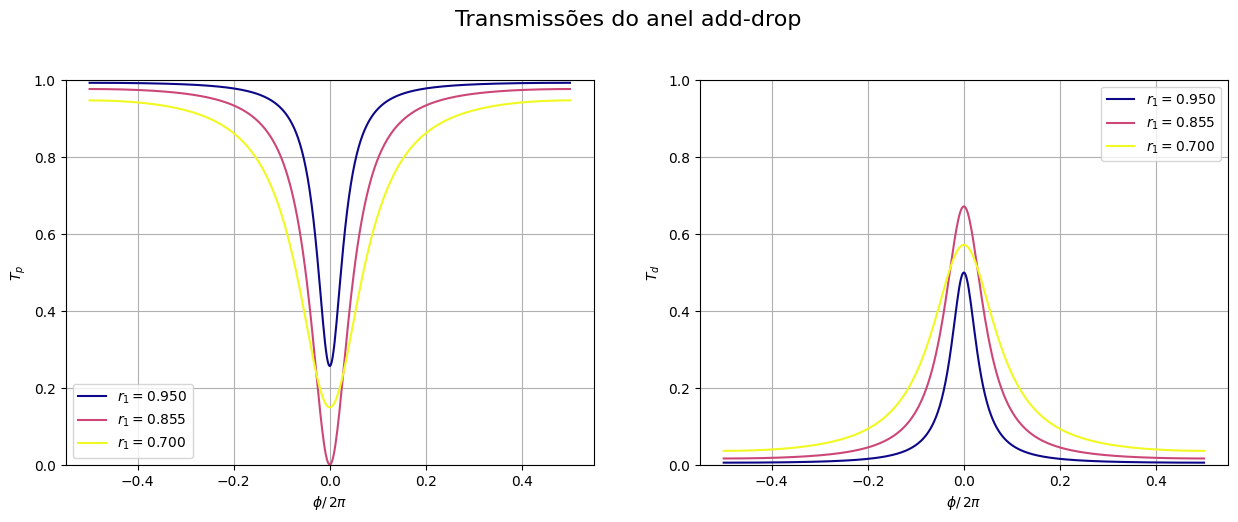

In [146]:
a = 0.95
r1_array = [0.950, 0.855, 0.700]
r2 = 0.90

phi_array = np.linspace(-pi, pi, 501)

Tp_matrix = []
Td_matrix = []

for r1 in r1_array:
    Tp_array = T_p(phi_array, r1, r2, a)
    Td_array = T_d(phi_array, r1, r2, a)

    Tp_matrix.append(Tp_array)
    Td_matrix.append(Td_array)

fig, ax = plt.subplots(1,2, figsize = (15,5))
fig.suptitle("Transmissões do anel add-drop", fontsize=16, y=1.02)

for k in range(0, len(r1_array), 1):
    ax[0].plot(phi_array/(2*pi), Tp_matrix[k], color=cmap2(k/(len(r1_array)-1)), label = r'$r_1=%.3f$' % r1_array[k])
    ax[1].plot(phi_array/(2*pi), Td_matrix[k], color=cmap2(k/(len(r1_array)-1)), label = r'$r_1=%.3f$' % r1_array[k])

ax[0].grid(True)
ax[0].set_xlabel(r'$\phi/\,2\pi$')
ax[0].set_ylabel(r'$T_p$')
ax[0].legend(loc='lower left')
ax[0].set_ylim(0,1)

ax[1].grid(True)
ax[1].set_xlabel(r'$\phi/\,2\pi$')
ax[1].set_ylabel(r'$T_d$')
ax[1].legend(loc='upper right')
ax[1].set_ylim(0,1)

plt.show()

## FSR ##

A FSR de um anel ressonante é o comprimento espectral entre dois comprimentos de onda de ressonância consecutivos. Ela é dada por:

$$FSR_\lambda = \frac{\lambda^2}{n_gL}\,,$$

Onde $\lambda$ é o comprimento de onda central de operação. A FSR em frequência é dada por:

$$FSR_f = \frac{c}{n_gL}$$

In [147]:
def FSR_lambda(L, lambda_ = lambda_, n_g=ng):
    num = lambda_**2
    den = n_g*L
    return num/den

def FSR_f(L, n_g=ng):
    num = c
    den = n_g*L
    return num/den

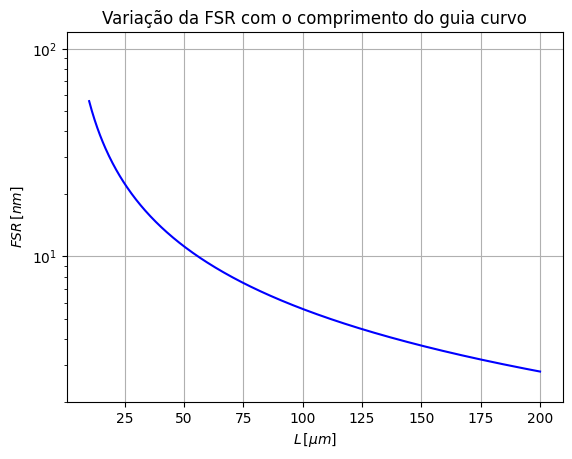

In [148]:
L_array = np.linspace(10,200,501)*um

FSR_array = FSR_lambda(L_array, n_g = 4.3)

plt.semilogy(L_array/um, FSR_array/nm, color = 'blue')
plt.grid(True)
plt.xlabel(r'$L\,[\mu m]$')
plt.ylabel(r'$FSR\,[nm]$')
plt.title('Variação da FSR com o comprimento do guia curvo')
plt.ylim(2,120)
plt.show()

# Projeto de anel add-drop para filtro WDM #

Projeto de um filtro add-drop para WDM com extração de 1 em cada 16 canais com grade de $200\,GHz$. 

1) $FSR=200\cdot 16 = 3200\,GHz$;
2) $FWHM = 100\,GHz\,(0,8\,nm)\rightarrow Q=\frac{1550\,nm}{0,8\,nm}\approx 2000$;
3) Guia SOI: $400\times 180\,nm$, $n_g=4.63$;
4) Perdas desprezadas ($a=1$);
5) Acopladores simétricos ($r_1=r_2=r$).

Parâmetros calculados:

$$L\approx 20,2\,\mu m\,,$$
$$r\approx 0,952\rightarrow L_c\approx 1,4\,\mu m\,.$$

Como $L_c$ é muito pequeno, no projeto, considera-se $L_c = 0$, e o guia curvo vira um guia circular com raio $R$,

$$R=\frac{L}{2\pi}\approx 3,21\,\mu m\,.$$

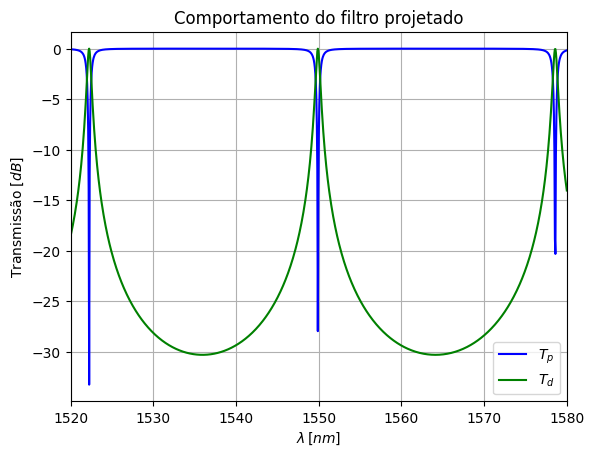

In [155]:
a = 1
r = 0.97
L = 20.2*um
n_eff = 4.22 #4.604
lambda_array = np.linspace(1520,1580,1001)*nm

phi_array = phi(lambda_array, L, n_eff)
Tp_array = T_p(phi_array, r, r, a)
Td_array = T_d(phi_array, r, r, a)

Tp_dB_array = 10*np.log10(Tp_array)
Td_dB_array = 10*np.log10(Td_array)

plt.plot(lambda_array/nm, Tp_dB_array, color = 'blue', label = '$T_p$')
plt.plot(lambda_array/nm, Td_dB_array, color = 'green', label = r'$T_d$')
plt.grid(True)
plt.xlabel(r'$\lambda\,[nm]$')
plt.ylabel(r'Transmissão [$dB$]')
plt.legend(loc = 'best')
plt.title('Comportamento do filtro projetado')
plt.xlim([1520,1580])
plt.show()